# 4 - Overview of the session

In [19]:
import os

# go to the project root, then run the reading part to get the data
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

%run notebooks/01_reading.ipynb

Header line information in 'data\001MoDe_R1.csv':
  screenWidth: 1104.0
  screenHeight: 661.0
  cornerX: 302.0
  cornerY: 80.0
  centerX: 552.0
  centerY: 330.0
  externalRadius: 250.0
  internalRadius: 170.0
  borderRadius: 1.0
  cursorRadius: 16.0
  indexOfDifficulty: 28.00696429476858
  taskRadius: 209.5
  taskTolerance: 47.0
  borderColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  autoStart: 3600.0
  cycleMaxNumber: 6.0
  cycleDuration: 20.0
  software: LSL-mouse
  version: 1.2.0rc5
  task: CircularTarget
  isWithLSL: false
Same header in both files: True
Markers in 'data\001MoDe_R1.marker.csv':
1616776712325: KeyTyped=32 DoCycleChange
1616776712331: DoCycleChange:DoStartCycleTimedSequence
1616776712333: DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
1616776732336: DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
1616776752340: 

### Raw time series data
Position of the mouse over the whole session, in centered coordinates: the center of the circle is at (0, 0), and the y axis points up (on the screen, y points down, so we use center Y - y).
Black dashed lines = start of each record (DoRecord), red dashed lines = end (DoPause).

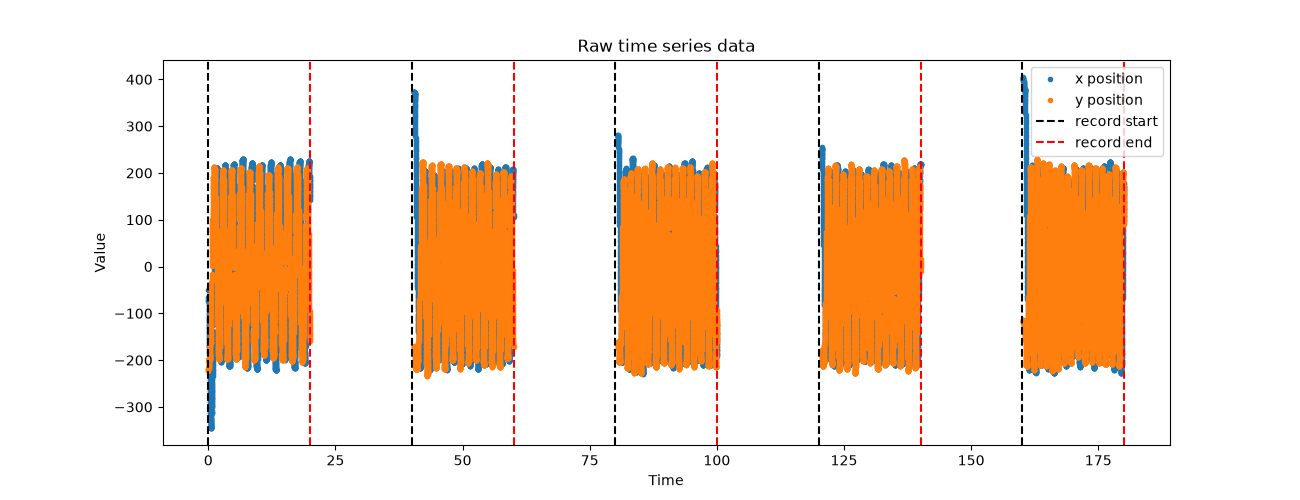

In [20]:
# centered coordinates: center of the circle = (0, 0), y axis pointing up
x_c = x - params["centerX"]
y_c = params["centerY"] - y

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(t, x_c, ".", label="x position")
ax.plot(t, y_c, ".", label="y position")

# vertical lines at the start (black) and end (red) of each record
for i in range(n_records):
    ax.axvline(t_starts[i], color="black", linestyle="--", label="record start" if i == 0 else None)
    ax.axvline(t_ends[i], color="red", linestyle="--", label="record end" if i == 0 else None)

ax.set_title("Raw time series data")
ax.set_xlabel("Time")
ax.set_ylabel("Value")
ax.legend()
plt.show()

**Explanation** :

We can see 5 records of about 20 s, separated by pauses of about 20 s without data: in this version of MouseReMoCo (1.2), the mouse position is only recorded during the records.
The 6th record planned in the configuration is missing because "q" was pressed during the 5th pause.

In each record, x and y oscillate between about -210 and +210 px around 0 (the center of the circle).
This is what a circular movement looks like when x and y are plotted separately : one oscillation = one lap. The amplitude (about 210 px) matches the task radius (taskRadius = 209.5 px).
The number of oscillations increases from about 11 in record 1 to about 15 in record 5: the participant becomes faster (1.84 s per lap in record 1, 1.30 s in record 5).

At the beginning of each record, x goes beyond the circle (down to about -340 px in record 1, up to about +400 px in record 5): the cursor is not yet in the target when the record starts.
This is why the statistics are only computed after the cursor enters the target for the first time.

### Raw trajectory data
Trajectory of the mouse in the plane (x vs y) for the 5 records.
Red circles = limits of the zone allowed for the cursor center:
170 + 16 = 186 px (internal radius + cursor radius) and 250 - 16 - 1 = 233 px
(external radius - cursor radius - border). Green points = cursor inside the target.

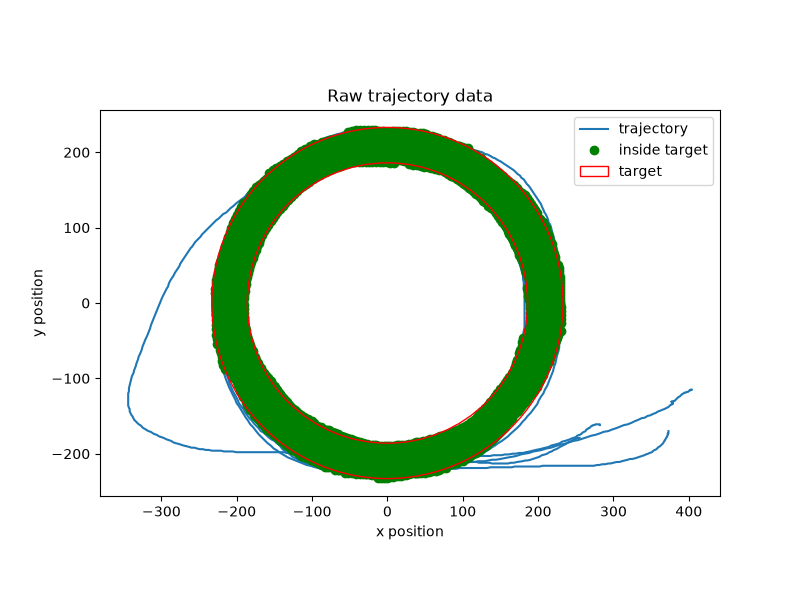

In [21]:
# limits of the zone allowed for the cursor center
r_in = params["internalRadius"] + params["cursorRadius"]                              # 186 px
r_out = params["externalRadius"] - params["cursorRadius"] - params["borderRadius"]    # 233 px
inside = in_target == 1

fig, ax = plt.subplots(figsize=(8, 6))

# trajectory of each record (no line drawn between two records)
for i in range(n_records):
    keep = (t >= t_starts[i]) & (t <= t_ends[i])
    ax.plot(x_c[keep], y_c[keep], color="tab:blue", label="trajectory" if i == 0 else None)

# green points = cursor inside the target
ax.plot(x_c[inside], y_c[inside], "o", color="green", label="inside target")

# red circles = limits of the target (drawn on top with zorder=3)
ax.add_patch(Circle((0, 0), r_out, fill=False, color="red", zorder=3, label="target"))
ax.add_patch(Circle((0, 0), r_in, fill=False, color="red", zorder=3))

ax.set_aspect("equal")   # same scale for x and y, so the circle is round
ax.set_title("Raw trajectory data")
ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.legend()
plt.show()

Most of the trajectory stays inside the target (green ring between 186 and 233 px): the participant follows the circle well, which matches the small error values of the MouseReMoCo table (between 0.13 % and 3.90 % of the lap outside the target).

The blue lines outside the ring are mainly the beginnings of the records: a large loop on the left for record 1, and lines coming from the bottom right
for the other records, where the cursor was before entering the target.
A few small excursions outside the ring are also visible during the laps.

This plot confirms that the mouseInTarget column is consistent with the geometry of the task: the green points (mouseInTarget = 1) are all between the two red circles.

# 5 - Plot trajectory of each record

For each record, we plot the trajectory of the mouse (x vs y) in a separate figure (Figure 3 to 7).

The coordinates are centered on the circle.
The yellow ring is the target, the magenta rectangle is the screen, and the points are green when the cursor is inside the target and red when it is outside.

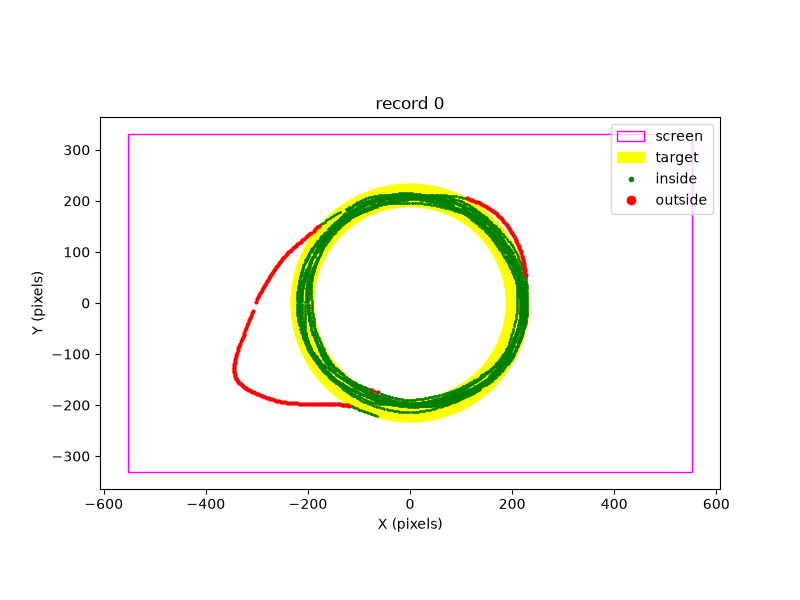

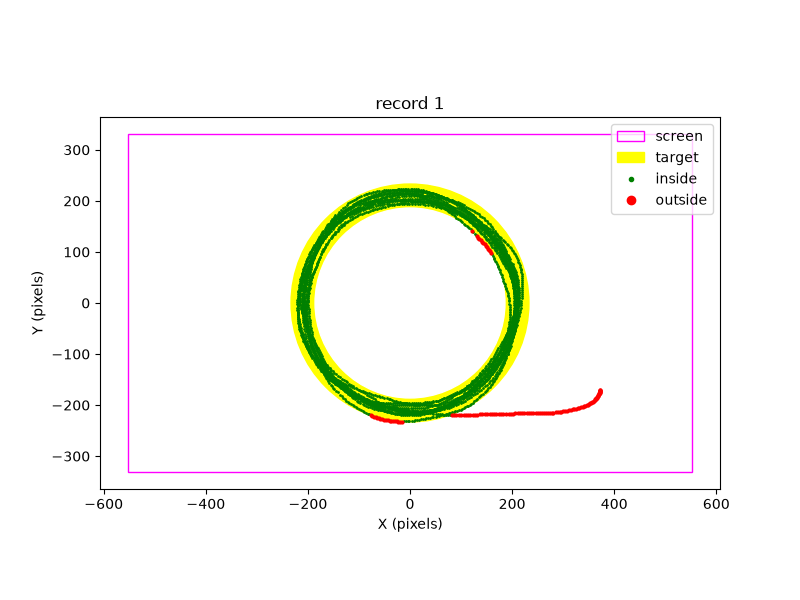

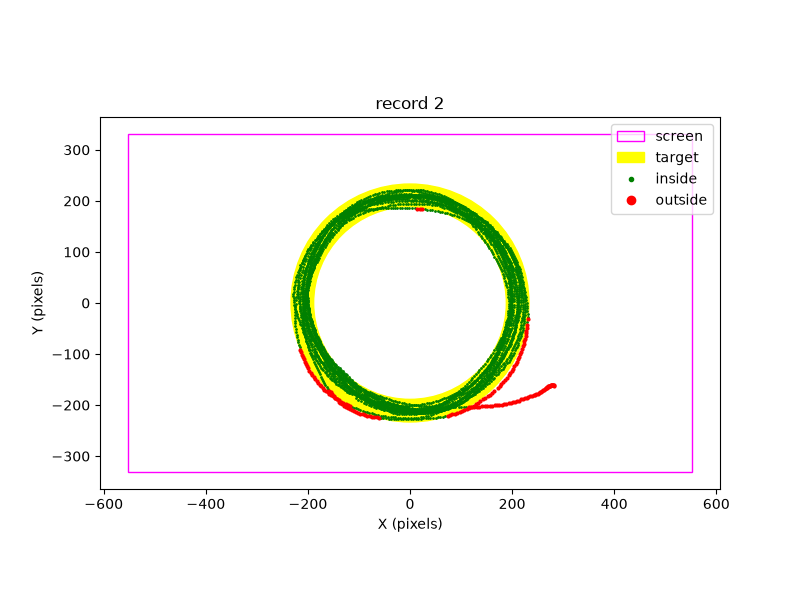

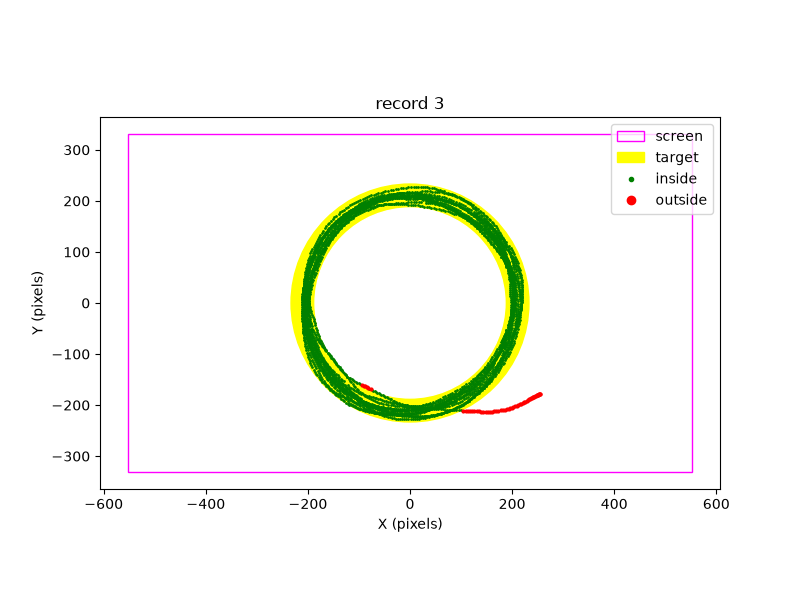

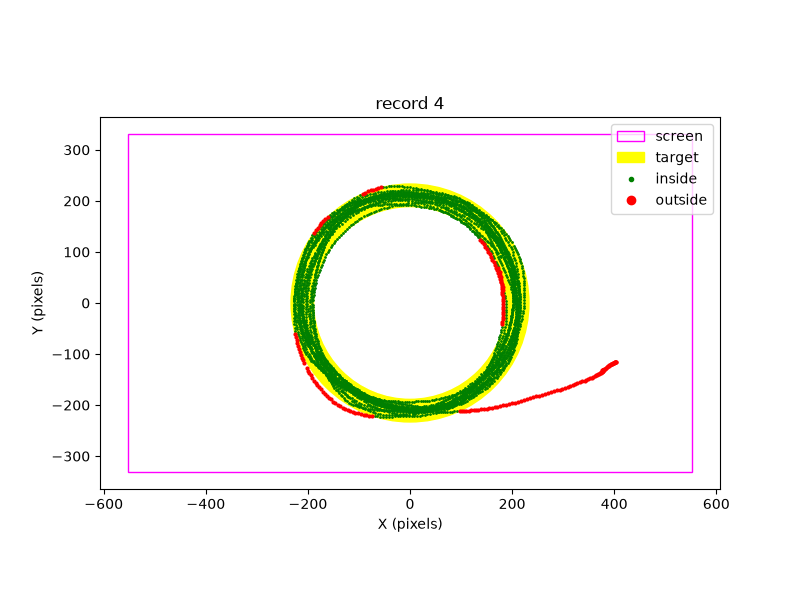

In [22]:
plt.close("all") # start from scratch each time the cell is run

first_fig = 3 # number of the first figure of this task (Figure 3 to 7)

# center of the circle and half-size of the screen (read from the header)
cx, cy = params["centerX"], params["centerY"]
half_w = params["screenWidth"] / 2
half_h = params["screenHeight"] / 2

# limits of the zone allowed for the cursor center (edges of the ring minus the cursor)
r_in = params["internalRadius"] + params["cursorRadius"]                              # 186 px
r_out = params["externalRadius"] - params["cursorRadius"] - params["borderRadius"]    # 233 px

for i in range(n_records):
    # centered coordinates: center of the circle = (0, 0), y axis pointing up
    # (on the screen y points down, so we use center Y - y)
    xi = x_trials[i] - cx
    yi = cy - y_trials[i]
    inside = in_target_trials[i] == 1 # True when the cursor is inside the target

    fig, ax = plt.subplots(num=first_fig + i, figsize=(8, 6))

    # screen (magenta rectangle)
    ax.add_patch(Rectangle((-half_w, -half_h), 2 * half_w, 2 * half_h,
                           fill=False, edgecolor="magenta", label="screen"))
    # target ring (yellow): a yellow disk (r_out) with a white disk (r_in) on top of it
    # zorder=0 and 1 keep both below the points (zorder=2)
    ax.add_patch(Circle((0, 0), r_out, color="yellow", zorder=0, label="target"))
    ax.add_patch(Circle((0, 0), r_in, color="white", zorder=1))

    # points inside the target (small, green) and outside (bigger, red)
    ax.plot(xi[inside], yi[inside], ".", color="green", markersize=2, label="inside")
    ax.plot(xi[~inside], yi[~inside], ".", color="red", markersize=4, label="outside")

    ax.set_aspect("equal") # same scale for x and y, so the circle is round
    ax.autoscale_view() # automatically set the limits of the axes to fit the data and the shapes
    ax.set_title(f"record {i}")
    ax.set_xlabel("X (pixels)")
    ax.set_ylabel("Y (pixels)")

    # legend of this figure (markerscale makes the small dots visible in the legend)
    ax.legend(loc="upper right", markerscale=3)
    plt.show()

### Observations

We can see that the way into the ring is not the same for every record. In records 1 to 4, the trajectory starts outside the ring (red points), on the right of the circle (x between 250 and 400 px), and goes left along the bottom of the ring. In record 0, the cursor starts inside the ring, at the bottom of the circle (green points), then goes out to make a wide loop on the left (down to about x = -340 px, red points) before coming back into the ring.

Once inside the ring, we see more green points than red points, which indicates that the trajectory was globally well followed. The red points are located at the edges of the ring (sometimes close to the inner edge, sometimes close to the outer edge). Records 1 and 3 have very few red points, which is consistent with their small errors in the MouseReMoCo table (0.74 % and 0.13 %). Records 0, 2 and 4 have more red points.

# 6 - Distance to the center (r) and angle (θ)

In [23]:
# distance to the center (r) and angle (theta) for each record
r_trials = []
theta_trials = []

for i in range(n_records):
    # centered coordinates: center of the circle = (0, 0), y axis pointing up
    xi = x_trials[i] - params["centerX"]
    yi = params["centerY"] - y_trials[i]

    r_trials.append(np.sqrt(xi**2 + yi**2))   # distance to the center (pixels)
    theta_trials.append(np.arctan2(yi, xi))   # angle (radians, between -pi and pi)

### Distance to the center over time
For each record, we plot the distance between the cursor and the center of the circle (r) over time (Figure 8).
Red dashed lines = limits of the zone allowed for the cursor center (186 and 233 px, as in task 5).
This figure is used to check the target limits and to see when the cursor enters the ring at the beginning of each record (needed for task 7).

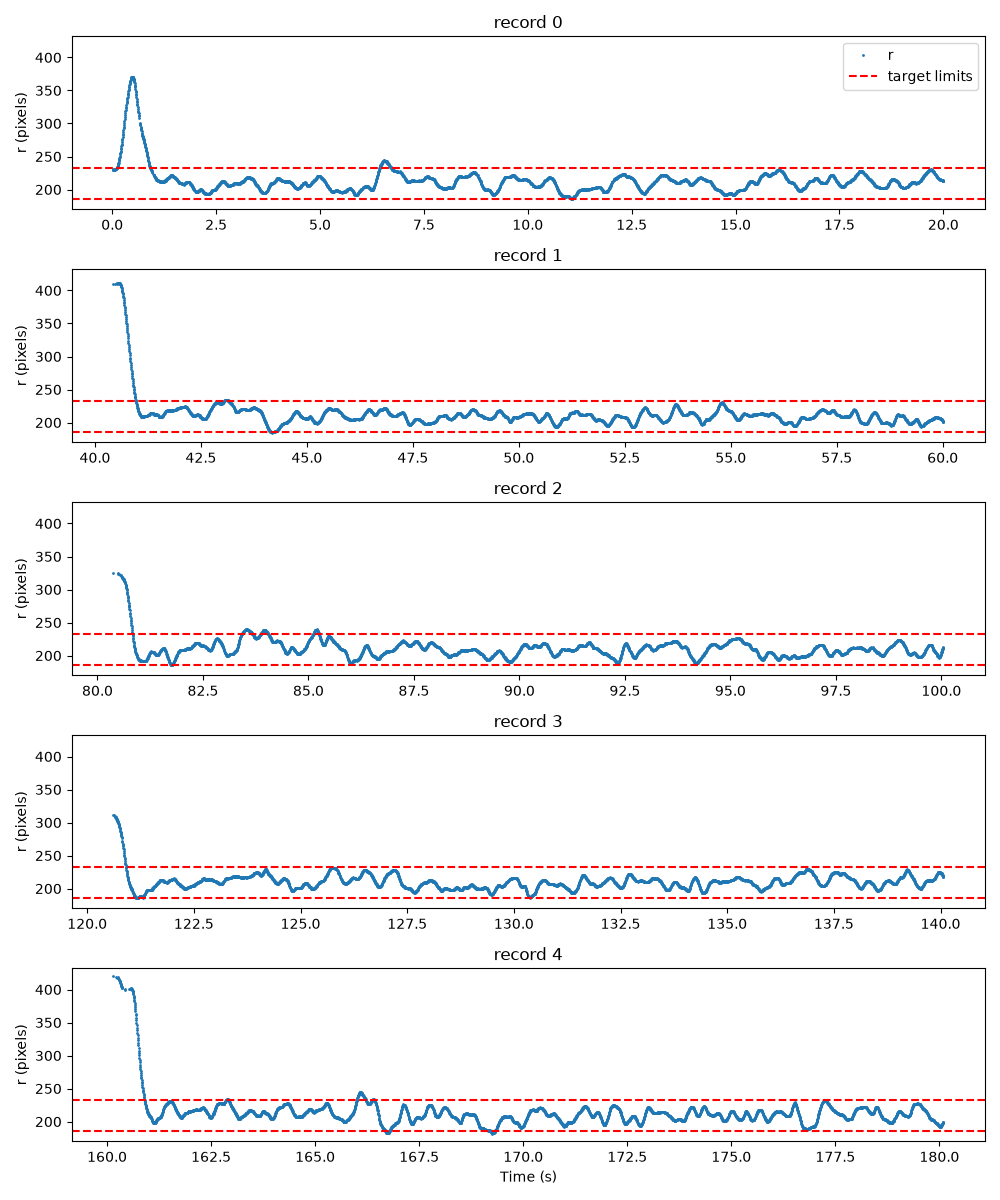

In [24]:
plt.close("all")

# distance to the center over time, with the limits of the target (186 and 233 px)
fig, axs = plt.subplots(n_records, 1, num=8, figsize=(10, 12), sharey=True)

for i in range(n_records):
    axs[i].plot(t_trials[i], r_trials[i], ".", markersize=2, label="r")
    axs[i].axhline(r_in, color="red", linestyle="--", label="target limits")
    axs[i].axhline(r_out, color="red", linestyle="--")
    axs[i].set_title(f"record {i}")
    axs[i].set_ylabel("r (pixels)")

axs[0].legend(loc="upper right")
axs[-1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()

### x, y and mouseInTarget over time
For each record, we plot the x and y positions (centered coordinates) and the mouseInTarget column over time (Figure 9 to 13), as in the figures of the assignment.
mouseInTarget = 1 when the cursor is inside the target, 0 when it is outside.

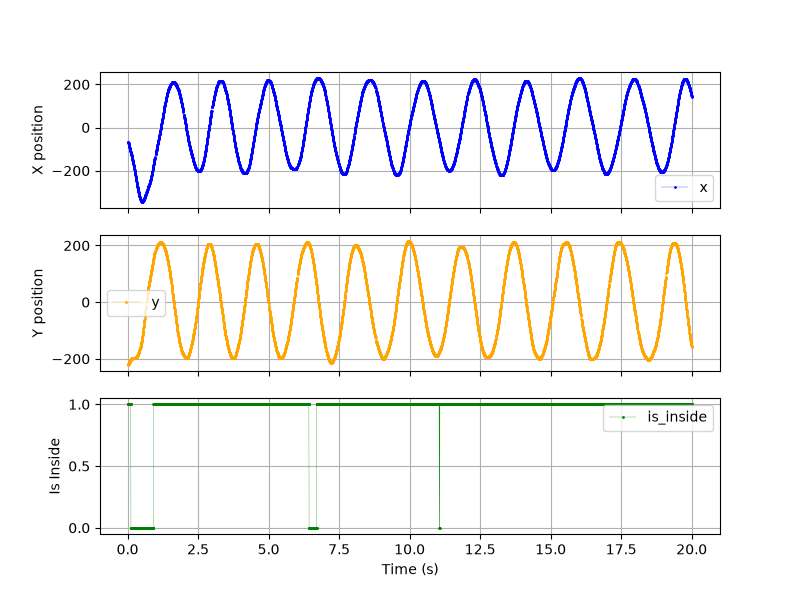

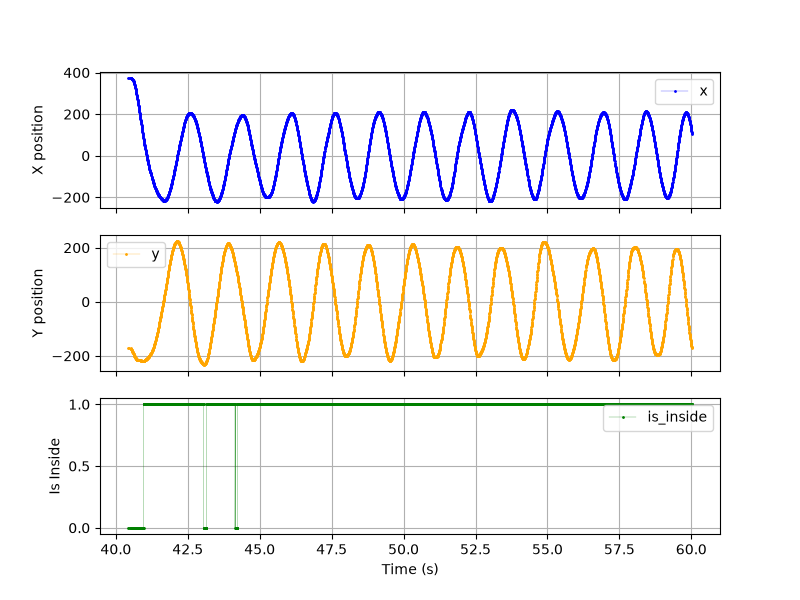

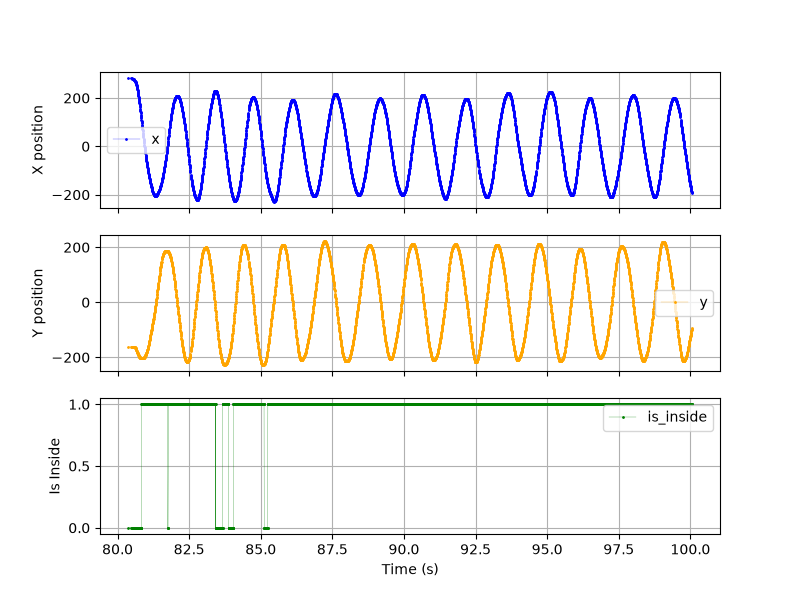

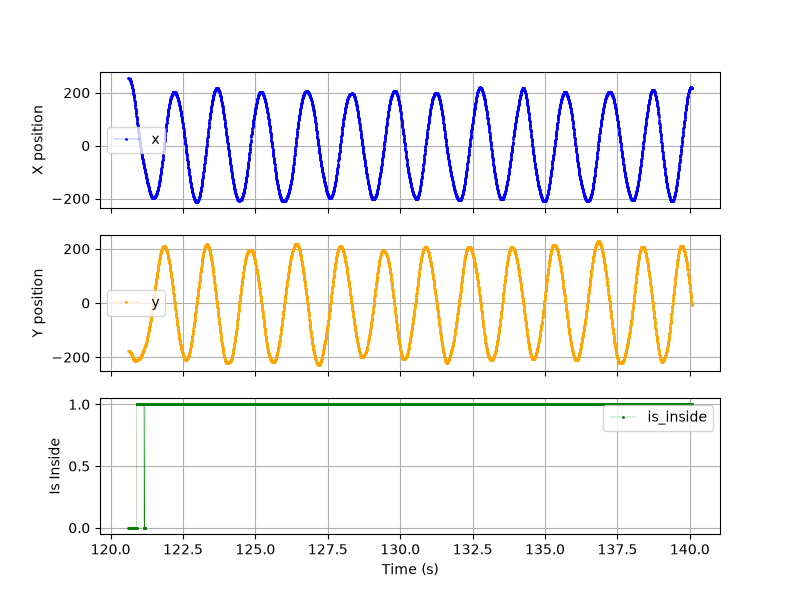

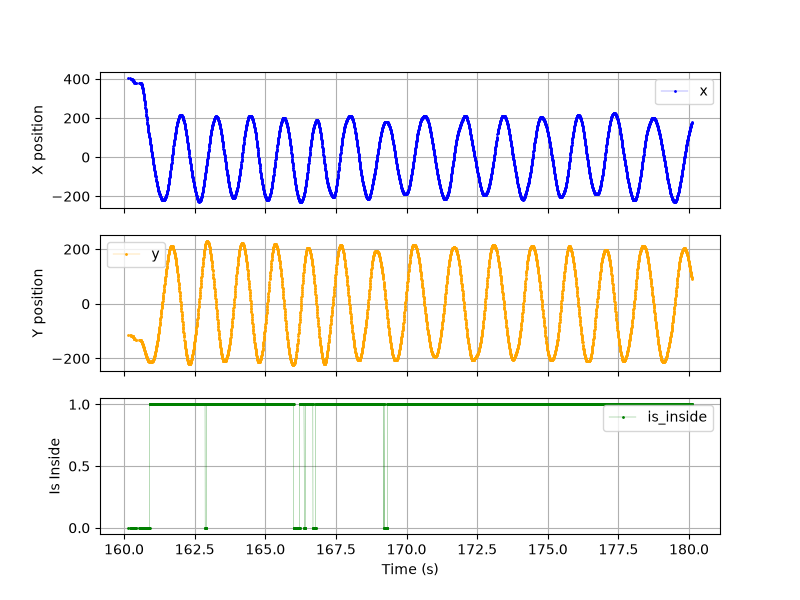

In [25]:
first_fig = 9  # number of the first figure of this cell (Figure 9 to 13)

for i in range(n_records):
    # centered coordinates, as in the trajectory figures
    xi = x_trials[i] - params["centerX"]
    yi = params["centerY"] - y_trials[i]

    fig, axs = plt.subplots(3, 1, num=first_fig + i, figsize=(8, 6), sharex=True)

    axs[0].plot(t_trials[i], xi, ".-", color="blue", linewidth=0.2, markersize=2, label="x")
    axs[1].plot(t_trials[i], yi, ".-", color="orange", linewidth=0.2, markersize=2, label="y")
    axs[2].plot(t_trials[i], in_target_trials[i], ".-", color="green", linewidth=0.2, markersize=2, label="is_inside")

    axs[0].set_ylabel("X position")
    axs[1].set_ylabel("Y position")
    axs[2].set_ylabel("Is Inside")
    axs[2].set_xlabel("Time (s)")

    for ax in axs:
        ax.grid()
        ax.legend()

    plt.show()